Imports

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

import re
import json

from hazm import Normalizer
from hazm import word_tokenize
from hazm import stopwords_list
from hazm import Stemmer

from collections import Counter

import torch
from torch.utils.data import Dataset
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

Loading the data

In [29]:
df = pd.read_csv('data.csv', encoding='utf-8')

df.to_csv('new_data.csv', index=False, encoding='utf-8-sig')

In [30]:
df.head()

,Text,Score,Suggestion
0,این اولین تجربه من برای خرید ایفون هست امروز...,100,1
1,خرید این محصول رو توصیه میکنم,84,1
2,1 ساله این گوشی رو دارم هیچ نقطه ضعفی ازش ند...,60,1
3,سلام خدمت دوستان این گوشی از همه نظر عالی کیف...,96,1
4,سلام دوستانی که نگران شکستن صفحه نمایش هستند ا...,92,1


In [31]:
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3261 entries, 0 to 3260
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Text        3261 non-null   object
 1   Score       3261 non-null   int64 
 2   Suggestion  3261 non-null   int64 
dtypes: int64(2), object(1)
memory usage: 76.6+ KB
None
             Score  Suggestion
count  3261.000000  3261.00000
mean     74.719411     1.41061
std      21.514015     0.72408
min       0.000000     1.00000
25%      60.000000     1.00000
50%      80.000000     1.00000
75%      92.000000     2.00000
max     100.000000     3.00000


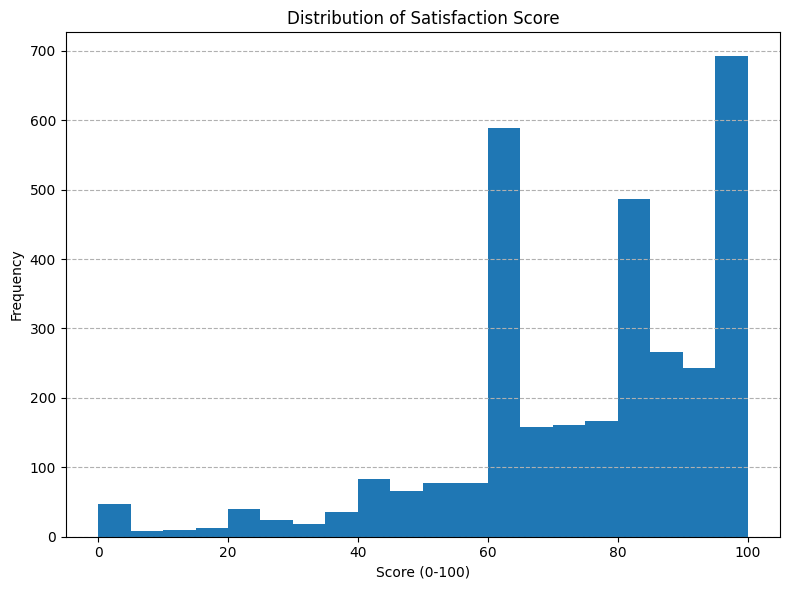

In [78]:
plt.figure(figsize=(8, 6))
plt.hist(df['Score'], bins=20)

plt.title("Distribution of Satisfaction Score")
plt.xlabel("Score (0-100)")
plt.ylabel("Frequency")
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()


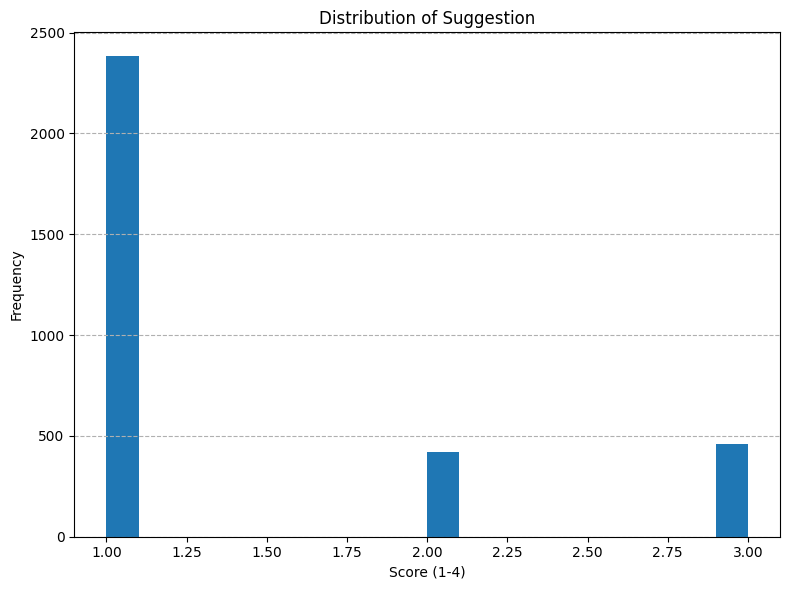

In [79]:
plt.figure(figsize=(8, 6))
plt.hist(df['Suggestion'], bins=20)

plt.title("Distribution of Suggestion")
plt.xlabel("Score (1-4)")
plt.ylabel("Frequency")
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()

PreProcess

1. Normalization

In [32]:
# # Save a copy of original data for comparison
original_texts = df.copy()

# Create a normalizer instance ('persian_style=True' is valid)
# normalizer = Normalizer(persian_style=True)
normalizer = Normalizer()

# Normalization function to apply to each text entry
def preprocess_text(text):
    # Normalize text using hazm
    normalized_text = normalizer.normalize(text)
    
    return normalized_text

# Apply preprocessing to the 'Text' column
df['Text'] = df['Text'].apply(preprocess_text)


In [33]:
def replace_zwnj_with_space(text):
    return text.replace('\u200c', ' ')

def count_zwnj(text):
    return text.count('\u200c')

total_zwnj_org = original_texts['Text'].apply(count_zwnj).sum()
print(f"Total ZWNJ characters in dataset orginial: {total_zwnj_org}")

print("\nAfter Normalization: ")
total_zwnj_before = df['Text'].apply(count_zwnj).sum()
print(f"Total ZWNJ characters in dataset before: {total_zwnj_before}")

df['Text'] = df['Text'].apply(replace_zwnj_with_space)

total_zwnj_after = df['Text'].apply(count_zwnj).sum()
print(f"Total ZWNJ characters in dataset after: {total_zwnj_after}")


Total ZWNJ characters in dataset orginial: 0

After Normalization: 
Total ZWNJ characters in dataset before: 7241
Total ZWNJ characters in dataset after: 0


Checking some of the changes

In [34]:
# Function to count Persian, English, and Arabic digits in a text
def count_digits(text):
    # Count Persian digits (۰ تا ۹)
    persian_digits = len(re.findall(r'[۰۱۲۳۴۵۶۷۸۹]', text))
    
    # Count English digits (0 to 9)
    english_digits = len(re.findall(r'[0-9]', text))
    
    # Count Arabic digits (٠ تا ٩)
    arabic_digits = len(re.findall(r'[٠١٢٣٤٥٦٧٨٩]', text))
    
    return persian_digits, english_digits, arabic_digits

print("Original text digits: \n")
# Apply the function to the 'Text' column
org_digit_counts = original_texts['Text'].apply(count_digits)

# making a new dataset of original digits count
df_org_digits = pd.DataFrame(org_digit_counts.tolist(), columns=['org_Persian_Digits', 'org_English_Digits', 'org_Arabic_Digits'])

# display(df_org_digits.head())
print(df_org_digits['org_Arabic_Digits'].sum())
print(df_org_digits['org_English_Digits'].sum())
print(df_org_digits['org_Persian_Digits'].sum())


# print("\n\nNormalized text digits: \n")

# # Apply the function to the 'Text' column
# digit_counts = df['Text'].apply(count_digits)

# # making a new dataset of normalized digits count
# df_norm_digits = pd.DataFrame(digit_counts.tolist(), columns=['norm_Persian_Digits', 'norm_English_Digits', 'norm_Arabic_Digits'])

# display(df_norm_digits.head())

Original text digits: 

0
4265
0


In [35]:
# Checking for Arabic characters before normalization
arabic_chars_pattern = r'[ك|ي|ة]'
original_arabic_chars = original_texts['Text'].str.contains(arabic_chars_pattern, regex=True).sum()
normalized_arabic_chars = df['Text'].str.contains(arabic_chars_pattern, regex=True).sum()

print(f'Before Normalization (Arabic Characters Count): {original_arabic_chars}')
print(f'After Normalization (Arabic Characters Count): {normalized_arabic_chars}')


Before Normalization (Arabic Characters Count): 0
After Normalization (Arabic Characters Count): 0


In [36]:
# Checking for diacritics before and after normalization
diacritics_pattern = r'[\u0617-\u061A\u064B-\u0652]'

original_diacritics = original_texts['Text'].str.contains(diacritics_pattern, regex=True).sum()
normalized_diacritics = df['Text'].str.contains(diacritics_pattern, regex=True).sum()

print(f'Before Normalization (Diacritics Count): {original_diacritics}')
print(f'After Normalization (Diacritics Count): {normalized_diacritics}')


Before Normalization (Diacritics Count): 99
After Normalization (Diacritics Count): 0


In [37]:
# Checking for half-spaces before and after normalization
half_space_pattern = r'\u200c'
original_half_spaces = original_texts['Text'].str.contains(half_space_pattern, regex=True).sum()
normalized_half_spaces = df['Text'].str.contains(half_space_pattern, regex=True).sum()

print(f'Before Normalization (Half-Spaces Count): {original_half_spaces}')
print(f'After Normalization (Half-Spaces Count): {normalized_half_spaces}')

Before Normalization (Half-Spaces Count): 0
After Normalization (Half-Spaces Count): 0


In [38]:
# Checking for extra spaces before and after normalization
original_extra_spaces = original_texts['Text'].str.contains(r'\s{2,}', regex=True).sum()
normalized_extra_spaces = df['Text'].str.contains(r'\s{2,}', regex=True).sum()

print(f'Before Normalization (Extra Spaces Count): {original_extra_spaces}')
print(f'After Normalization (Extra Spaces Count): {normalized_extra_spaces}')


Before Normalization (Extra Spaces Count): 2220
After Normalization (Extra Spaces Count): 0


Remove Punctuation and Noise

In [39]:
def count_punctuation(text):
    return len(re.findall(r'[^\w\s\u0600-\u06FF\u06F0-\u06F9]', text))

def remove_punctuation_and_noise(text):
    punctuation_pattern = r'[^\w\s\u0600-\u06FF\u06F0-\u06F9]'
    text = re.sub(punctuation_pattern, ' ', text)

    return text

org_punc = original_texts['Text'].apply(count_punctuation)
print("Original puncs count: ", org_punc.sum())


print("\nNormalized puncs amount: ")
norm_before_puncs = df['Text'].apply(count_punctuation)
print("Total punctuation before:", norm_before_puncs.sum())


df['Text'] = df['Text'].apply(remove_punctuation_and_noise)

norm_after_puncs = df['Text'].apply(count_punctuation)
print("Total punctuation after:", norm_after_puncs.sum())


Original puncs count:  0

Normalized puncs amount: 
Total punctuation before: 0
Total punctuation after: 0


Tokenization

In [40]:
# Tokenize a single string into words
def tokenize_text(text):
    return word_tokenize(text)

df['Tokens'] = df['Text'].apply(tokenize_text)


In [41]:
df['Tokens'][0]

['این',
 'اولین',
 'تجربه',
 'من',
 'برای',
 'خرید',
 'ایفون',
 'هست',
 'امروز',
 'ب',
 'دستم',
 'رسیده',
 'به',
 'اسم',
 'طلایی',
 'هست',
 'ولی',
 'دراصل',
 'رزگلده',
 'خیلی',
 'هم',
 'خوش',
 'رنگ',
 'هست']

Removing stopwords

In [42]:
# Load default Persian stopwords
stop_words = set(stopwords_list())

# Remove stopwords from token list
def remove_stopwords(tokens):
    return [token for token in tokens if token not in stop_words]


df['Tokens_NoStop'] = df['Tokens'].apply(remove_stopwords)


In [43]:
df['Tokens_NoStop'][0]

['تجربه',
 'خرید',
 'ایفون',
 'هست',
 'امروز',
 'ب',
 'دستم',
 'رسیده',
 'اسم',
 'طلایی',
 'هست',
 'دراصل',
 'رزگلده',
 'خوش',
 'رنگ',
 'هست']

In [44]:
empty_after_stopwords = df[df['Tokens_NoStop'].apply(lambda x: len(x) == 0)]
empty_after_stopwords

,Text,Score,Suggestion,Tokens,Tokens_NoStop
166,عالی,60,1,[عالی],[]
923,بسیار عالی,76,1,"[بسیار, عالی]",[]
1121,همیشه عالی,60,1,"[همیشه, عالی]",[]
1363,بسیار عالی,84,1,"[بسیار, عالی]",[]
1520,عالی,100,1,[عالی],[]
1633,خیلی خوب است,92,1,"[خیلی, خوب, است]",[]
2345,بسیار عالی,88,1,"[بسیار, عالی]",[]
2397,عالی از همه نظر,60,1,"[عالی, از, همه, نظر]",[]
2589,خیلی خوب است,60,1,"[خیلی, خوب, است]",[]
2657,تا حالا که خیلی خوب بوده,76,1,"[تا, حالا, که, خیلی, خوب, بوده]",[]


In [48]:
stop_words = stopwords_list()

print(stop_words[:20])

['آخرین', 'آقای', 'آمد', 'آمده', 'آمده_است', 'آن', 'آنان', 'آنجا', 'آنها', 'آنچه', 'آنکه', 'آورد', 'آوری', 'آیا', 'ابتدا', 'اثر', 'اجرا', 'اخیر', 'از', 'است']


In [49]:
a = 'عالی' in stop_words
b = 'خیلی' in stop_words

print(a)
print(b)

True
True


In [50]:
# Load default Persian stopwords
stop_words = set(stopwords_list())

# =========
# after some checking we removed the words that might be important

stop_words.discard('عالی')
stop_words.discard('خوب')
# =========

# Remove stopwords from token list
def remove_stopwords(tokens):
    return [token for token in tokens if token not in stop_words]


df['Tokens_NoStop'] = df['Tokens'].apply(remove_stopwords)


In [51]:
empty_after_stopwords = df[df['Tokens_NoStop'].apply(lambda x: len(x) == 0)]
empty_after_stopwords

,Text,Score,Suggestion,Tokens,Tokens_NoStop


Stemming

In [52]:
stemmer = Stemmer()

# Apply stemming to each token
def stem_tokens(tokens):
    return [stemmer.stem(token) for token in tokens]

df['Stemmed_Tokens'] = df['Tokens_NoStop'].apply(stem_tokens)

In [53]:
df.head()

,Text,Score,Suggestion,Tokens,Tokens_NoStop,Stemmed_Tokens
0,این اولین تجربه من برای خرید ایفون هست امروز ب...,100,1,"[این, اولین, تجربه, من, برای, خرید, ایفون, هست...","[تجربه, خرید, ایفون, هست, امروز, ب, دستم, رسید...","[تجربه, خرید, ایفون, هس, امروز, ب, دس, رسیده, ..."
1,خرید این محصول رو توصیه می کنم,84,1,"[خرید, این, محصول, رو, توصیه, می, کنم]","[خرید, محصول, توصیه]","[خرید, محصول, توصیه]"
2,۱ ساله این گوشی رو دارم هیچ نقطه ضعفی ازش ندیدم,60,1,"[۱, ساله, این, گوشی, رو, دارم, هیچ, نقطه, ضعفی...","[۱, گوشی, دارم, نقطه, ضعفی, ازش, ندیدم]","[۱, گوش, دار, نقطه, ضعف, از, ندید]"
3,سلام خدمت دوستان این گوشی از همه نظر عالی کیفی...,96,1,"[سلام, خدمت, دوستان, این, گوشی, از, همه, نظر, ...","[سلام, خدمت, دوستان, گوشی, عالی, کیفیت, ساخت, ...","[سلا, خدم, دوس, گوش, عال, کیف, ساخ, سرع, کیف, ..."
4,سلام دوستانی که نگران شکستن صفحه نمایش هستند ا...,92,1,"[سلام, دوستانی, که, نگران, شکستن, صفحه, نمایش,...","[سلام, دوستانی, نگران, شکستن, صفحه, نمایش, بدو...","[سلا, دوستان, نگر, شکستن, صفحه, نما, بدونند, ص..."


３.	آماده‌سازی داده‌ها برای مدل

تعریف واژگان (Vocabulary) از روی توکن‌ها


نگاشت کلمات به اندیس‌های عددی


تبدیل متن‌ها به دنباله‌هایی از اعداد


In [54]:
# Flatten the list of token lists into a single list of all tokens
all_tokens = [token for sublist in df['Stemmed_Tokens'] for token in sublist]

# Count the frequency of each token
word_counts = Counter(all_tokens)

sorted_word_counts = word_counts.most_common()

# Build the vocabulary dictionary: each unique word gets a unique index (starting from 2)
# Index 0 and 1 are reserved for special tokens: <PAD> and <UNK>
vocab = {word: idx + 2 for idx, (word, _) in enumerate(word_counts.most_common())}

# Add special tokens to the vocabulary
vocab['<PAD>'] = 0
vocab['<UNK>'] = 1


In [55]:
# Print first 10 items
for word, count in sorted_word_counts[:10]:
    print(f"{word}: {count}")

: 2142
خرید: 1331
هس: 1243
کیف: 1215
داره: 1204
استفاده: 884
کار: 833
صدا: 827
یه: 752
میشه: 724


In [56]:
# Save the vocabulary to a JSON file
with open('vocab.json', 'w', encoding='utf-8') as f:
    json.dump(vocab, f, ensure_ascii=False, indent=4)


# # Load the vocabulary from the JSON file
# with open('vocab.json', 'r', encoding='utf-8') as f:
#     loaded_vocab = json.load(f)


In [57]:
def tokens_to_indices(tokens, vocab):
    return [vocab.get(token, vocab['<UNK>']) for token in tokens]

df['Token_Indices'] = df['Stemmed_Tokens'].apply(lambda x: tokens_to_indices(x, vocab))

In [58]:
df.head()

,Text,Score,Suggestion,Tokens,Tokens_NoStop,Stemmed_Tokens,Token_Indices
0,این اولین تجربه من برای خرید ایفون هست امروز ب...,100,1,"[این, اولین, تجربه, من, برای, خرید, ایفون, هست...","[تجربه, خرید, ایفون, هست, امروز, ب, دستم, رسید...","[تجربه, خرید, ایفون, هس, امروز, ب, دس, رسیده, ...","[311, 3, 2748, 4, 176, 133, 46, 546, 148, 1432..."
1,خرید این محصول رو توصیه می کنم,84,1,"[خرید, این, محصول, رو, توصیه, می, کنم]","[خرید, محصول, توصیه]","[خرید, محصول, توصیه]","[3, 27, 214]"
2,۱ ساله این گوشی رو دارم هیچ نقطه ضعفی ازش ندیدم,60,1,"[۱, ساله, این, گوشی, رو, دارم, هیچ, نقطه, ضعفی...","[۱, گوشی, دارم, نقطه, ضعفی, ازش, ندیدم]","[۱, گوش, دار, نقطه, ضعف, از, ندید]","[93, 51, 60, 288, 177, 38, 322]"
3,سلام خدمت دوستان این گوشی از همه نظر عالی کیفی...,96,1,"[سلام, خدمت, دوستان, این, گوشی, از, همه, نظر, ...","[سلام, خدمت, دوستان, گوشی, عالی, کیفیت, ساخت, ...","[سلا, خدم, دوس, گوش, عال, کیف, ساخ, سرع, کیف, ...","[41, 437, 48, 51, 20, 5, 52, 92, 5, 9, 91, 358..."
4,سلام دوستانی که نگران شکستن صفحه نمایش هستند ا...,92,1,"[سلام, دوستانی, که, نگران, شکستن, صفحه, نمایش,...","[سلام, دوستانی, نگران, شکستن, صفحه, نمایش, بدو...","[سلا, دوستان, نگر, شکستن, صفحه, نما, بدونند, ص...","[41, 309, 681, 2340, 44, 95, 4771, 44, 4772, 2..."


یکنواخت‌سازی طول دنباله‌ها با Padding

In [59]:
# Convert lists of indices into tensors
sequences = [torch.tensor(seq, dtype=torch.long) for seq in df['Token_Indices']]

# Pad sequences to the same length (batch_first=True makes shape: [batch, seq_len])
padded_sequences = pad_sequence(sequences, batch_first=True, padding_value=vocab['<PAD>'])

In [60]:
print(padded_sequences.shape)
padded_sequences

torch.Size([3261, 712])


tensor([[ 311,    3, 2748,  ...,    0,    0,    0],
        [   3,   27,  214,  ...,    0,    0,    0],
        [  93,   51,   60,  ...,    0,    0,    0],
        ...,
        [  16,   48,   60,  ...,    0,    0,    0],
        [2329, 1430, 9088,  ...,    0,    0,    0],
        [ 292,   67,    8,  ...,    0,    0,    0]])

In [65]:
df['Seq_Length'] = df['Token_Indices'].apply(len)


print("Mean length:", df['Seq_Length'].mean())
print("Max length:", df['Seq_Length'].max())
print("Min length:", df['Seq_Length'].min())

Mean length: 30.81539405090463
Max length: 712
Min length: 1


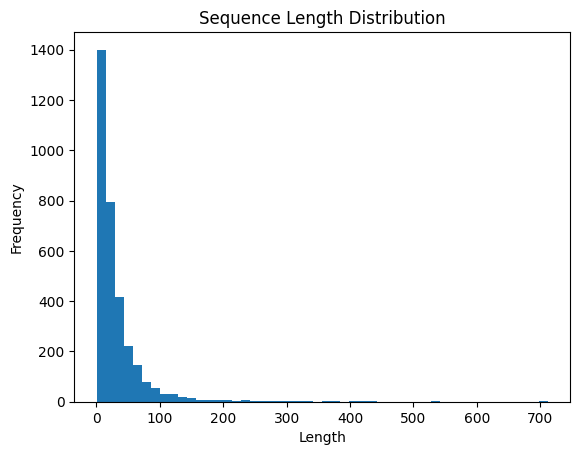

In [66]:
plt.hist(df['Seq_Length'], bins=50)
plt.title("Sequence Length Distribution")
plt.xlabel("Length")
plt.ylabel("Frequency")
plt.show()


In [69]:
lengths = df['Seq_Length']
threshold = lengths.quantile(0.97)  # np.percentile(lengths, 97)
print(f"97% of sequences have length ≤ {int(threshold)}")


97% of sequences have length ≤ 123


In [71]:
MAX_LEN = 123
padded_sequences = padded_sequences[:, :MAX_LEN]

padded_sequences.shape

torch.Size([3261, 123])

پیاده‌سازی کلاس Dataset سفارشی در PyTorch

In [80]:
# Count the frequency of each unique value in the 'Suggestion' column
print("Count of each value in 'Suggestion':")
print(df['Suggestion'].value_counts().sort_index())

# Check if there are any values outside the expected range [1, 2, 3]
invalid_values = df[~df['Suggestion'].isin([1, 2, 3])]

if not invalid_values.empty:
    # If there are invalid values, print them
    print("\nInvalid values found in 'Suggestion':")
    print(invalid_values['Suggestion'].unique())
else:
    # Otherwise, confirm all values are valid
    print("\nAll values in 'Suggestion' are valid (1, 2, 3).")


Count of each value in 'Suggestion':
Suggestion
1    2382
2     419
3     460
Name: count, dtype: int64

All values in 'Suggestion' are valid (1, 2, 3).


In [81]:
class TextDataset(Dataset):
    def __init__(self, sequences, labels):
        self.sequences = sequences          # tensor of padded input sequences
        self.labels = torch.tensor(labels)  # tensor of labels

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        return self.sequences[idx], self.labels[idx]


In [82]:
label_map = {1: 0, 2: 1, 3: 2}

df['label'] = df['Suggestion'].map(label_map)

dataset = TextDataset(padded_sequences, df['label'].values)

In [99]:
df.head()

,Text,Score,Suggestion,Tokens,Tokens_NoStop,Stemmed_Tokens,Token_Indices,Seq_Length,label
0,این اولین تجربه من برای خرید ایفون هست امروز ب...,100,1,"[این, اولین, تجربه, من, برای, خرید, ایفون, هست...","[تجربه, خرید, ایفون, هست, امروز, ب, دستم, رسید...","[تجربه, خرید, ایفون, هس, امروز, ب, دس, رسیده, ...","[311, 3, 2748, 4, 176, 133, 46, 546, 148, 1432...",16,0
1,خرید این محصول رو توصیه می کنم,84,1,"[خرید, این, محصول, رو, توصیه, می, کنم]","[خرید, محصول, توصیه]","[خرید, محصول, توصیه]","[3, 27, 214]",3,0
2,۱ ساله این گوشی رو دارم هیچ نقطه ضعفی ازش ندیدم,60,1,"[۱, ساله, این, گوشی, رو, دارم, هیچ, نقطه, ضعفی...","[۱, گوشی, دارم, نقطه, ضعفی, ازش, ندیدم]","[۱, گوش, دار, نقطه, ضعف, از, ندید]","[93, 51, 60, 288, 177, 38, 322]",7,0
3,سلام خدمت دوستان این گوشی از همه نظر عالی کیفی...,96,1,"[سلام, خدمت, دوستان, این, گوشی, از, همه, نظر, ...","[سلام, خدمت, دوستان, گوشی, عالی, کیفیت, ساخت, ...","[سلا, خدم, دوس, گوش, عال, کیف, ساخ, سرع, کیف, ...","[41, 437, 48, 51, 20, 5, 52, 92, 5, 9, 91, 358...",17,0
4,سلام دوستانی که نگران شکستن صفحه نمایش هستند ا...,92,1,"[سلام, دوستانی, که, نگران, شکستن, صفحه, نمایش,...","[سلام, دوستانی, نگران, شکستن, صفحه, نمایش, بدو...","[سلا, دوستان, نگر, شکستن, صفحه, نما, بدونند, ص...","[41, 309, 681, 2340, 44, 95, 4771, 44, 4772, 2...",32,0


In [83]:
batch_size = 32

train_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

In [84]:
for X_batch, y_batch in train_loader:
    print("Batch inputs shape:", X_batch.shape)
    print("Batch labels shape:", y_batch.shape)
    break # just 1 batch test

Batch inputs shape: torch.Size([32, 123])
Batch labels shape: torch.Size([32])


تعریف مدل

In [85]:
class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, pad_idx):
        super(SentimentLSTM, self).__init__()
        
        # 1. Embedding Layer
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)

        # 2. LSTM Layer (can replace with GRU if needed)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True)

        # 3. Dropout + Fully Connected Layer
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        # x shape: [batch_size, sequence_length]
        embedded = self.embedding(x)                     # [batch_size, seq_len, embedding_dim]
        lstm_out, (hidden, cell) = self.lstm(embedded)   # hidden: [1, batch_size, hidden_dim]
        output = self.dropout(hidden[-1])                # get last hidden state
        output = self.fc(output)                         # [batch_size, output_dim]
        return output


In [90]:
print(padded_sequences.shape[1])
print(len(label_map))

123
3


In [91]:
vocab_size = len(vocab)
embedding_dim = 100
hidden_dim = padded_sequences.shape[1]
# hidden_dim = 123 # the size of the padding vector
output_dim = len(label_map)
# output_dim = 3 # size of different labels
pad_idx = vocab['<PAD>']

model = SentimentLSTM(vocab_size, embedding_dim, hidden_dim, output_dim, pad_idx)


In [92]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)


Using device: cuda


In [93]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=0.001)

In [95]:
model.to(device)

print(next(model.parameters()).device)  # cuda:0

cuda:0


In [97]:
num_epochs = 50  # or any desired number of epochs

for epoch in range(num_epochs):
    model.train()  # set the model to training mode
    total_loss = 0

    for batch in train_loader:
        inputs, labels = batch  # batch contains [batch_size, seq_len], [batch_size]
        
        # for using gpu
        inputs = inputs.to(device)
        labels = labels.to(device)

        # Forward pass: compute model predictions
        outputs = model(inputs)  # shape: [batch_size, num_classes]

        # Compute loss
        loss = criterion(outputs, labels)

        # Zero out gradients from previous step
        optimizer.zero_grad()

        # Backward pass: compute gradients
        loss.backward()

        # Update model weights
        optimizer.step()

        # Accumulate batch loss
        total_loss += loss.item()

    # Compute and print average loss for the epoch
    avg_loss = total_loss / len(train_loader)
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}")


Epoch [1/50], Loss: 0.7548
Epoch [2/50], Loss: 0.7547
Epoch [3/50], Loss: 0.7526
Epoch [4/50], Loss: 0.7506
Epoch [5/50], Loss: 0.7525
Epoch [6/50], Loss: 0.7501
Epoch [7/50], Loss: 0.7486
Epoch [8/50], Loss: 0.7453
Epoch [9/50], Loss: 0.7455
Epoch [10/50], Loss: 0.7466
Epoch [11/50], Loss: 0.7401
Epoch [12/50], Loss: 0.7342
Epoch [13/50], Loss: 0.7324
Epoch [14/50], Loss: 0.7493
Epoch [15/50], Loss: 0.7495
Epoch [16/50], Loss: 0.7297
Epoch [17/50], Loss: 0.7275
Epoch [18/50], Loss: 0.7224
Epoch [19/50], Loss: 0.7165
Epoch [20/50], Loss: 0.7138
Epoch [21/50], Loss: 0.7093
Epoch [22/50], Loss: 0.7114
Epoch [23/50], Loss: 0.7023
Epoch [24/50], Loss: 0.6984
Epoch [25/50], Loss: 0.6937
Epoch [26/50], Loss: 0.6934
Epoch [27/50], Loss: 0.6910
Epoch [28/50], Loss: 0.6922
Epoch [29/50], Loss: 0.6885
Epoch [30/50], Loss: 0.6894
Epoch [31/50], Loss: 0.6968
Epoch [32/50], Loss: 0.6927
Epoch [33/50], Loss: 0.6898
Epoch [34/50], Loss: 0.6551
Epoch [35/50], Loss: 0.6384
Epoch [36/50], Loss: 0.6180
E

ارزیابی مدل

تقسیم داده به Train / Validation

In [98]:
train_texts, val_texts, train_labels, val_labels = train_test_split(
    padded_sequences, df['label'].values, test_size=0.2, random_state=42, stratify=df['label']
)

In [100]:
train_dataset = TextDataset(train_texts, train_labels)
val_dataset = TextDataset(val_texts, val_labels)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32)

ارزیابی با معیارهای استاندارد

Epoch [1/10], Train Loss: 0.3500
Validation Accuracy: 0.7259
Precision: 0.8169 | Recall: 0.7259 | F1 Score: 0.7535
------------------------------------------------------------
Best model saved at epoch 1 with F1 Score: 0.7535
Epoch [2/10], Train Loss: 0.3456
Validation Accuracy: 0.7198
Precision: 0.8038 | Recall: 0.7198 | F1 Score: 0.7444
------------------------------------------------------------
Epoch [3/10], Train Loss: 0.3318
Validation Accuracy: 0.7289
Precision: 0.8032 | Recall: 0.7289 | F1 Score: 0.7508
------------------------------------------------------------
Epoch [4/10], Train Loss: 0.3325
Validation Accuracy: 0.7213
Precision: 0.7950 | Recall: 0.7213 | F1 Score: 0.7459
------------------------------------------------------------
Epoch [5/10], Train Loss: 0.3238
Validation Accuracy: 0.7182
Precision: 0.7973 | Recall: 0.7182 | F1 Score: 0.7425
------------------------------------------------------------
Epoch [6/10], Train Loss: 0.3198
Validation Accuracy: 0.7152
Precision

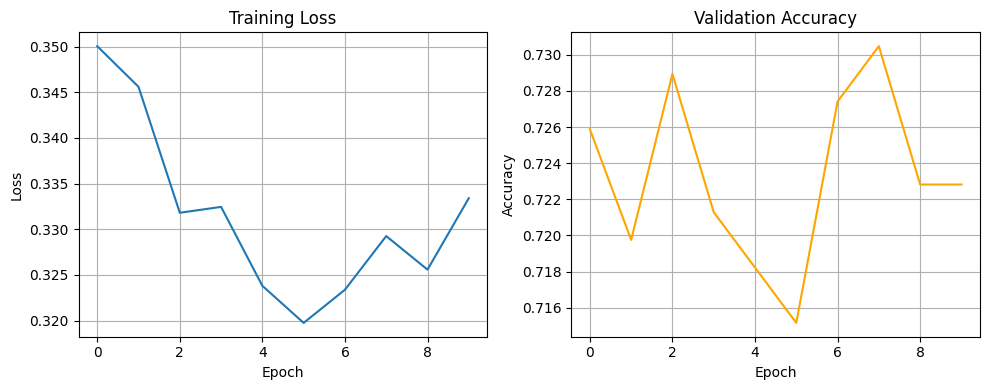


Best Validation Results:
Epoch: 8
Accuracy : 0.7305
Precision: 0.8069
Recall   : 0.7305
F1 Score : 0.7538

Sample Predictions from Validation Set:
Sample 1: True Label = 0 | Predicted = 2
Sample 2: True Label = 0 | Predicted = 0
Sample 3: True Label = 0 | Predicted = 0
Sample 4: True Label = 0 | Predicted = 0
Sample 5: True Label = 0 | Predicted = 0


In [105]:
train_losses = []
val_accuracies = []

best_f1 = 0.0
best_epoch = 0
best_model_path = "best_model.pt"
best_metrics = {"accuracy": 0, "precision": 0, "recall": 0, "f1": 0}

num_epochs = 10
model.to(device)

for epoch in range(num_epochs):
    model.train()
    total_loss = 0

    for inputs, labels in train_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    train_losses.append(avg_loss)
    print(f"Epoch [{epoch+1}/{num_epochs}], Train Loss: {avg_loss:.4f}")

    # -------- Evaluation --------
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            preds = torch.argmax(outputs, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds, average='weighted')
    recall = recall_score(all_labels, all_preds, average='weighted')
    f1 = f1_score(all_labels, all_preds, average='weighted')

    val_accuracies.append(acc)

    print(f"Validation Accuracy: {acc:.4f}")
    print(f"Precision: {precision:.4f} | Recall: {recall:.4f} | F1 Score: {f1:.4f}")
    print("-" * 60)

    # Save best model
    if f1 > best_f1:
        best_f1 = f1
        best_epoch = epoch + 1
        best_metrics = {
            "accuracy": acc,
            "precision": precision,
            "recall": recall,
            "f1": f1
        }
        torch.save(model.state_dict(), best_model_path)
        print(f"Best model saved at epoch {best_epoch} with F1 Score: {f1:.4f}")

# -------- Plotting Loss and Accuracy --------
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(val_accuracies, label='Validation Accuracy', color='orange')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Validation Accuracy")
plt.grid(True)

plt.tight_layout()
plt.show()

# -------- Show Best Evaluation Results --------
print("\nBest Validation Results:")
print(f"Epoch: {best_epoch}")
print(f"Accuracy : {best_metrics['accuracy']:.4f}")
print(f"Precision: {best_metrics['precision']:.4f}")
print(f"Recall   : {best_metrics['recall']:.4f}")
print(f"F1 Score : {best_metrics['f1']:.4f}")

# -------- Load best model and predict on sample data --------
print("\nSample Predictions from Validation Set:")
model.load_state_dict(torch.load(best_model_path))
model.eval()

for i in range(5):
    input_tensor = val_texts[i].unsqueeze(0).to(device)  # shape: [1, seq_len]
    label = val_labels[i]

    with torch.no_grad():
        output = model(input_tensor)
        pred = torch.argmax(output, dim=1).item()

    print(f"Sample {i+1}: True Label = {label} | Predicted = {pred}")
